# Valoriser un portefeuille de rentiers avec mortables

Ce notebook montre, en quelques lignes, comment valoriser un portefeuille de rentes viagères :

1. décrire les rentiers (dates de naissance, montant, réversion) ;
2. calculer l'engagement de chacun avec `life.annuity()` : rentes **mensuelles**, **âges exacts**, **réversion** ;
3. totaliser, puis mesurer l'effet d'un **choc de longévité** (qx × 0,80) et de la **table non genrée TGHF05**.

```bash
pip install "mortables[viz]"   # ou : uv add "mortables[viz]"
```

In [1]:
import pandas as pd

from mortables import get_table, life, viz

DATE_INVENTAIRE = "2026-12-31"
TAUX = 0.015   # taux technique annuel

## 1. Le portefeuille

In [2]:
rentiers = pd.DataFrame([
    # sexe, naissance, rente annuelle (€), réversion, naissance du conjoint
    ("M", "1956-04-12", 18_000, 0.6, "1958-09-30"),
    ("F", "1959-11-03", 12_500, 0.0, None),
    ("M", "1951-01-25", 24_000, 0.6, "1954-06-14"),
    ("F", "1948-07-19",  9_800, 0.0, None),
    ("M", "1962-02-08", 15_200, 1.0, "1964-12-01"),
    ("F", "1954-05-27", 20_400, 0.6, "1952-03-09"),
], columns=["sexe", "naissance", "rente", "reversion", "naissance_conjoint"])
rentiers

,sexe,naissance,rente,reversion,naissance_conjoint
0,M,1956-04-12,18000,0.6,1958-09-30
1,F,1959-11-03,12500,0.0,NaN
2,M,1951-01-25,24000,0.6,1954-06-14
3,F,1948-07-19,9800,0.0,NaN
4,M,1962-02-08,15200,1.0,1964-12-01
5,F,1954-05-27,20400,0.6,1952-03-09


## 2. Valorisation, tête par tête

Rente mensuelle à terme à échoir, tables TGH05 / TGF05 selon le sexe, génération = année de naissance, conjoint de sexe opposé.

In [3]:
TABLE = {"M": "TGH05", "F": "TGF05"}
AUTRE = {"M": "F", "F": "M"}

def engagement(r, table=None, ajuster=lambda t: t):
    def tbl(sexe, naissance):
        nom = table or TABLE[sexe]
        return ajuster(get_table(nom, generation=int(naissance[:4])))

    options = {}
    if r.reversion > 0:
        options = dict(
            reversion=r.reversion,
            spouse_table=tbl(AUTRE[r.sexe], r.naissance_conjoint),
            spouse_age=life.exact_age(r.naissance_conjoint, DATE_INVENTAIRE),
        )
    age = life.exact_age(r.naissance, DATE_INVENTAIRE)
    coef = life.annuity(tbl(r.sexe, r.naissance), age, TAUX, frequency=12, **options)
    return r.rente * coef

rentiers["age"] = [
    round(life.exact_age(d, DATE_INVENTAIRE), 2) for d in rentiers.naissance
]
rentiers["engagement"] = [engagement(r) for r in rentiers.itertuples()]
rentiers[["sexe", "age", "rente", "reversion", "engagement"]].round({"engagement": 0})

,sexe,age,rente,reversion,engagement
0,M,70.72,18000,0.6,369180.0
1,F,67.16,12500,0.0,272269.0
2,M,75.93,24000,0.6,410318.0
3,F,78.45,9800,0.0,134528.0
4,M,64.89,15200,1.0,411518.0
5,F,72.60,20400,0.6,389275.0


In [4]:
total = rentiers.engagement.sum()
print(f"Engagement total : {total:,.0f} €".replace(",", " "))

Engagement total : 1 987 088 €


## 3. Sensibilités

- **Choc de longévité** de la formule standard Solvabilité 2 : qx × 0,80.
- **Table non genrée TGHF05** (arrêté du 18/11/2024), obligatoire pour les nouvelles rentes de retraite supplémentaire collective.

In [5]:
def longevite(t):
    return t.scaled(0.80)

choc = sum(engagement(r, ajuster=longevite) for r in rentiers.itertuples())
unisexe = sum(engagement(r, table="TGHF05") for r in rentiers.itertuples())

pd.DataFrame({
    "engagement (€)": [total, choc, unisexe],
    "écart": [0, choc / total - 1, unisexe / total - 1],
}, index=["TGH05 / TGF05", "choc longévité (qx × 0,80)", "TGHF05 (non genrée)"]
).style.format({"engagement (€)": "{:,.0f}", "écart": "{:+.2%}"})

,engagement (€),écart
TGH05 / TGF05,"1,987,088",+0.00%
"choc longévité (qx × 0,80)","2,110,549",+6.21%
TGHF05 (non genrée),"1,935,155",-2.61%


## 4. Visualiser les tables utilisées

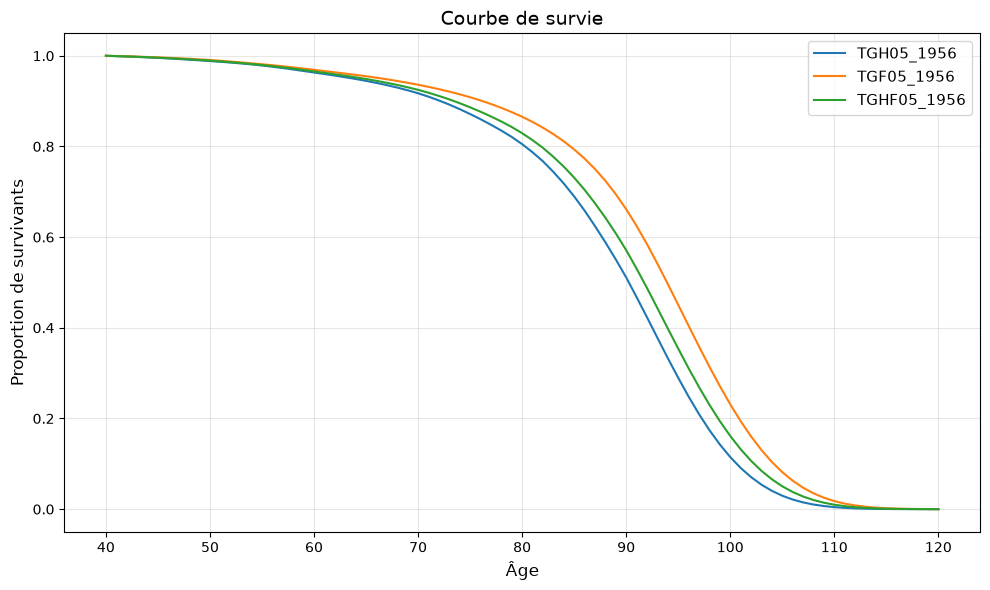

In [6]:
viz.plot_survival(["TGH05", "TGF05", "TGHF05"], generation=1956)